In [28]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [29]:
image = cv2.imread(r"C:\Users\Asus\OneDrive\Desktop\Computer_vision\images\shapes.jpg")

image_rgb = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

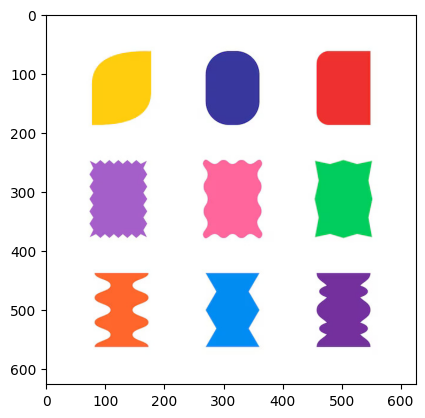

In [30]:
plt.imshow(image_rgb)

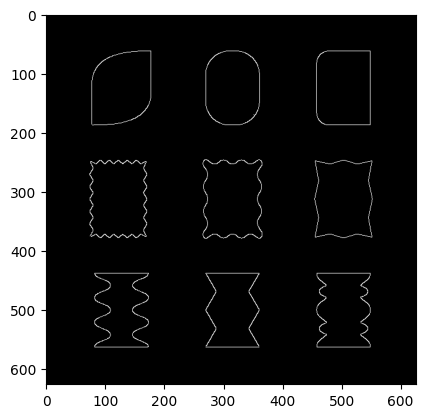

In [31]:
# Using Canny for detecting edges
gray = cv2.Canny(image_gray,80,150 )
plt.imshow(gray, cmap= "grey")

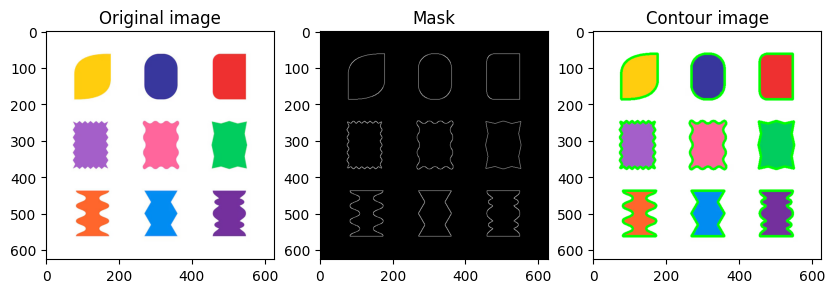

In [32]:
contours, hierarchy = cv2.findContours(gray,cv2.RETR_LIST,cv2.CHAIN_APPROX_SIMPLE)

# Mode - hierarchy relationship between contours

# Method - How contour points are stored

contour_image = image.copy()

cv2.drawContours(contour_image, contours, -1, (0,255,0), 5)

plt.figure(figsize=(10,5))
plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(image,cv2.COLOR_BGR2RGB))
plt.title("Original image")

plt.subplot(1,3,2)
plt.imshow(gray,cmap="grey")
plt.title("Mask")

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(contour_image,cv2.COLOR_BGR2RGB))
plt.title("Contour image")
plt.savefig(r"C:\Users\Asus\OneDrive\Desktop\Computer_vision\Contours/canny_output.png")
plt.show()

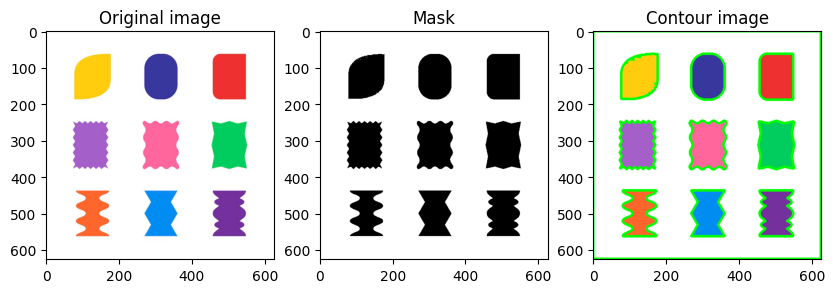

In [33]:
# Using Thresholding

retval, binary = cv2.threshold(image_gray, 200, 255, cv2.THRESH_BINARY)

contours, hierarchy = cv2.findContours(binary,cv2.RETR_LIST,cv2.CHAIN_APPROX_SIMPLE)

# Mode - hierarchy relationship between contours

# Method - How contour points are stored

contour_image = image.copy()

cv2.drawContours(contour_image, contours, -1, (0,255,0), 5)

plt.figure(figsize=(10,5))
plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(image,cv2.COLOR_BGR2RGB))
plt.title("Original image")

plt.subplot(1,3,2)
plt.imshow(binary,cmap="grey")
plt.title("Mask")

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(contour_image,cv2.COLOR_BGR2RGB))
plt.title("Contour image")
plt.savefig(r"C:\Users\Asus\OneDrive\Desktop\Computer_vision\Contours/thresholding_output.png")
plt.show()

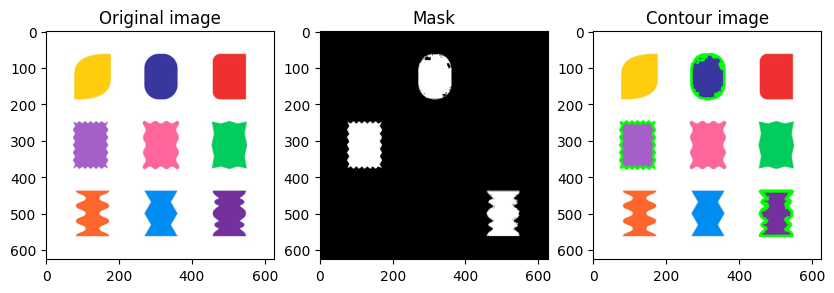

In [34]:
# Without Edge detection using inRange

lower_bound = np.array([120,100,0], dtype= np.uint8)
upper_bound = np.array([160,185,255], dtype = np.uint8)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

mask = cv2.inRange(image_hsv, lower_bound, upper_bound)

contours, hierarchy = cv2.findContours(mask,cv2.RETR_LIST,cv2.CHAIN_APPROX_SIMPLE)

# Mode - hierarchy relationship between contours

# Method - How contour points are stored

contour_image = image.copy()

cv2.drawContours(contour_image, contours, -1, (0,255,0), 5)

plt.figure(figsize=(10,5))
plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(image,cv2.COLOR_BGR2RGB))
plt.title("Original image")

plt.subplot(1,3,2)
plt.imshow(mask,cmap="grey")
plt.title("Mask")

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(contour_image,cv2.COLOR_BGR2RGB))
plt.title("Contour image")
plt.savefig(r"C:\Users\Asus\OneDrive\Desktop\Computer_vision\Contours/inrange_output.png")
plt.show()

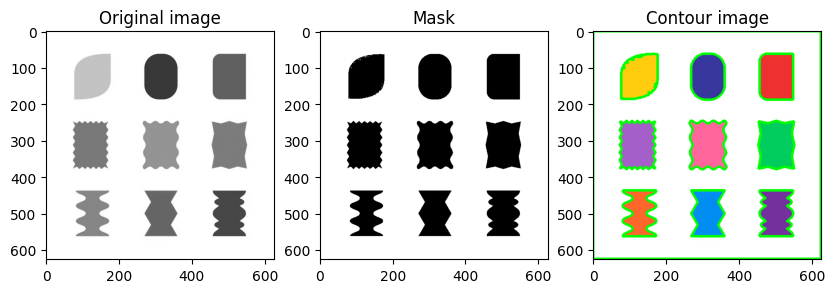

In [35]:
# Without Edge detection using inRange on Grayscale Image

lower_bound = np.array([200], dtype= np.uint8)
upper_bound = np.array([255], dtype = np.uint8)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

mask = cv2.inRange(image_gray, lower_bound, upper_bound)

contours, hierarchy = cv2.findContours(mask,cv2.RETR_LIST,cv2.CHAIN_APPROX_SIMPLE)

# Mode - hierarchy relationship between contours

# Method - How contour points are stored

contour_image = image.copy()

cv2.drawContours(contour_image, contours, -1, (0,255,0), 5)

plt.figure(figsize=(10,5))
plt.subplot(1,3,1)
plt.imshow(image_gray, cmap = "grey")
plt.title("Original image")

plt.subplot(1,3,2)
plt.imshow(mask,cmap="grey")
plt.title("Mask")

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(contour_image,cv2.COLOR_BGR2RGB))
plt.title("Contour image")
plt.savefig(r"C:\Users\Asus\OneDrive\Desktop\Computer_vision\Contours/inrange_gray_image_output.png")
plt.show()

In [36]:
# Without Edge detection using inRange on Grayscale Image

lower_bound = np.array([200], dtype= np.uint8)
upper_bound = np.array([255], dtype = np.uint8)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

mask = cv2.inRange(image_gray, lower_bound, upper_bound)

contours, hierarchy = cv2.findContours(mask,cv2.RETR_LIST,cv2.CHAIN_APPROX_SIMPLE)

sorted_contour= sorted(contours, key=cv2.contourArea, reverse= True )
print(len(sorted_contour))

contours = sorted_contour[1:10]


32


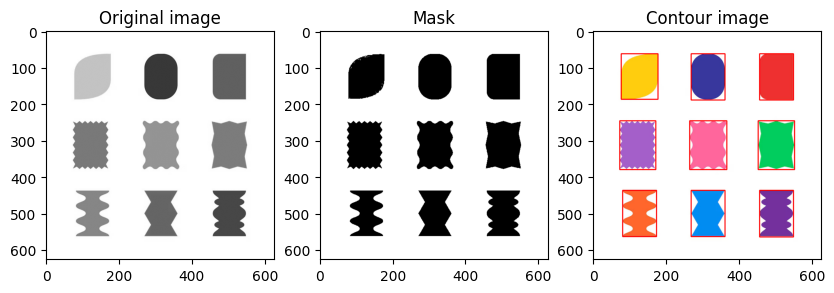

In [37]:
contour_image = image.copy()

for contour in contours:
    x, y, w, h = cv2.boundingRect(contour)
    cv2.rectangle(contour_image, (x,y), (x+w, y+h), (0,0,255), 2)

plt.figure(figsize=(10,5))
plt.subplot(1,3,1)
plt.imshow(image_gray, cmap = "grey")
plt.title("Original image")

plt.subplot(1,3,2)
plt.imshow(mask,cmap="grey")
plt.title("Mask")

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(contour_image,cv2.COLOR_BGR2RGB))
plt.title("Contour image")
plt.savefig(r"C:\Users\Asus\OneDrive\Desktop\Computer_vision\Contours/bounding_rectangle_output.png")
plt.show()